<a href="https://colab.research.google.com/github/nurtuasikal-cmyk/Project-UTS-Kelompok-7/blob/main/Jurnal_UAS_Kelompok_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Instalasi dan import library

In [ ]:
!pip -q install statsmodels scikit-learn openpyxl seaborn

import warnings, os, itertools, json
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from scipy.stats import jarque_bera

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
SEASONAL_PERIOD = 12
TRAIN_RATIO = 0.80

# Atur None untuk seluruh provinsi. Untuk uji coba awal, isi misalnya ['MALUKU'].
PROVINCE_FILTER = None

# Grid dibuat ringkas agar dapat dijalankan di Colab. Dapat diperluas setelah uji coba.
ORDER_CANDIDATES = [(1,1,1), (1,1,0), (0,1,1), (0,1,0)]
SEASONAL_CANDIDATES = [
    (1,1,1,SEASONAL_PERIOD),
    (0,1,1,SEASONAL_PERIOD)
]

print("Library siap.")


Library siap.


##1. Upload dan baca dataset

In [ ]:
uploaded = files.upload()  # Pilih Data Padi.xlsx
file_name = next(iter(uploaded.keys()))
raw = pd.read_excel(file_name)

print("Ukuran data:", raw.shape)
display(raw.head())
print("\nKolom:", raw.columns.tolist())


Saving Data Padi.xlsx to Data Padi (1).xlsx
Ukuran data: (3952, 6)


,Provinsi,Tahun,Bulan,Y,X,Curah_Hujan_mm
0,ACEH,2018,Januari,76118.47,14541.53,271.773066
1,ACEH,2018,Februari,142876.76,27075.77,107.421202
2,ACEH,2018,Maret,375841.91,66403.96,173.163008
3,ACEH,2018,April,336742.80,58507.03,235.422620
4,ACEH,2018,Mei,96372.36,16867.65,241.453734



Kolom: ['Provinsi', 'Tahun', 'Bulan', 'Y', 'X', 'Curah_Hujan_mm']


##2. Preprocessing dan validasi panel

In [ ]:
# Sesuaikan nama kolom bila file sumber berbeda.
required = ['Provinsi', 'Tahun', 'Bulan', 'Y', 'X', 'Curah_Hujan_mm']
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise ValueError(f"Kolom berikut tidak ditemukan: {missing_cols}")

# Dataset menggunakan ejaan "Nopember" dan memiliki spasi pada "Oktober ".
month_map = {
    'januari':1, 'februari':2, 'maret':3, 'april':4, 'mei':5, 'juni':6,
    'juli':7, 'agustus':8, 'september':9, 'oktober':10,
    'nopember':11, 'november':11, 'desember':12
}

df = raw.copy()
df['Provinsi'] = df['Provinsi'].astype(str).str.strip().str.upper()
df['bulan_num'] = (
    df['Bulan'].astype(str).str.strip().str.lower().map(month_map)
)

if df['bulan_num'].isna().any():
    print("Nama bulan yang belum dikenali:",
          df.loc[df['bulan_num'].isna(), 'Bulan'].unique())
    raise ValueError("Ada nama bulan yang tidak dikenali. Periksa kolom Bulan.")

df['Tanggal'] = pd.to_datetime({
    'year': df['Tahun'].astype(int),
    'month': df['bulan_num'].astype(int),
    'day': 1
})
df = df.rename(columns={'X':'X1', 'Curah_Hujan_mm':'X2'})
for c in ['Y','X1','X2']:
    df[c] = pd.to_numeric(df[c], errors='coerce')

print("Preprocessing berhasil!")
print("Missing values:\n", df[['Provinsi','Tanggal','Y','X1','X2']].isna().sum())
print("Duplikat provinsi-tanggal:", df.duplicated(['Provinsi','Tanggal']).sum())

if df[['Provinsi','Tanggal','Y','X1','X2']].isna().any().any():
    raise ValueError("Terdapat data kosong/tidak valid. Periksa dan tangani terlebih dahulu.")
if df.duplicated(['Provinsi','Tanggal']).any():
    raise ValueError("Terdapat duplikasi provinsi-tanggal.")

df = df.sort_values(['Provinsi','Tanggal']).reset_index(drop=True)

province_counts = df.groupby('Provinsi').size()
print("Jumlah provinsi:", df['Provinsi'].nunique())
print("Jumlah observasi per provinsi:\n", province_counts.value_counts().sort_index())

for prov, g in df.groupby('Provinsi'):
    expected = pd.date_range(g['Tanggal'].min(), g['Tanggal'].max(), freq='MS')
    if not g['Tanggal'].reset_index(drop=True).equals(pd.Series(expected)):
        print("PERINGATAN: urutan tanggal tidak lengkap/berurutan untuk", prov)

if PROVINCE_FILTER is not None:
    df = df[df['Provinsi'].isin([p.upper() for p in PROVINCE_FILTER])].copy()

provinces = sorted(df['Provinsi'].unique())
print(f"Provinsi dianalisis: {len(provinces)}")
display(df.groupby('Provinsi').agg(
    n=('Y','size'), awal=('Tanggal','min'), akhir=('Tanggal','max'),
    rata_produksi=('Y','mean')
).head(10))


Preprocessing berhasil!
Missing values:
 Provinsi    0
Tanggal     0
Y           0
X1          0
X2          0
dtype: int64
Duplikat provinsi-tanggal: 0
Jumlah provinsi: 38
Jumlah observasi per provinsi:
 104    38
Name: count, dtype: int64
Provinsi dianalisis: 38


,n,awal,akhir,rata_produksi
Provinsi,,,,
ACEH,104,2018-01-01,2026-08-01,135304.184904
BALI,104,2018-01-01,2026-08-01,51443.245769
BANTEN,104,2018-01-01,2026-08-01,140809.162308
BENGKULU,104,2018-01-01,2026-08-01,23409.349808
DI YOGYAKARTA,104,2018-01-01,2026-08-01,45496.376058
DKI JAKARTA,104,2018-01-01,2026-08-01,247.088750
GORONTALO,104,2018-01-01,2026-08-01,21032.537596
JAMBI,104,2018-01-01,2026-08-01,27037.837596
JAWA BARAT,104,2018-01-01,2026-08-01,779544.340769


##3. Eksplorasi data dan pembagian training-testing

In [ ]:
!pip -q install plotly

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, Markdown

# Pastikan urutan waktu dan tipe data benar
eda = df.copy()
eda['Tahun'] = eda['Tanggal'].dt.year
eda['Bulan_num'] = eda['Tanggal'].dt.month
month_names = ['Januari','Februari','Maret','April','Mei','Juni',
               'Juli','Agustus','September','Oktober','November','Desember']
eda['Nama_Bulan'] = pd.Categorical(
    eda['Bulan_num'].map(dict(enumerate(month_names, start=1))),
    categories=month_names, ordered=True
)

# ---------- A. Kartu ringkasan ----------
n_prov = eda['Provinsi'].nunique()
n_obs = len(eda)
date_min, date_max = eda['Tanggal'].min(), eda['Tanggal'].max()
n_months = eda.groupby('Provinsi')['Tanggal'].nunique().median()

summary_cards = pd.DataFrame({
    'Indikator': ['Jumlah provinsi','Total observasi','Periode pengamatan','Median bulan/provinsi'],
    'Nilai': [f'{n_prov:,}', f'{n_obs:,}',
              f'{date_min:%b %Y} – {date_max:%b %Y}', f'{int(n_months)} bulan']
})
display(Markdown("### A. Ringkasan dataset"))
display(summary_cards.style.hide(axis='index').set_properties(**{
    'font-size':'13pt', 'text-align':'center'
}).set_table_styles([{'selector':'th','props':[('background-color','#17365D'),
                                               ('color','white'),
                                               ('text-align','center')]}]))

# ---------- B. Statistik deskriptif ----------
display(Markdown("### B. Statistik deskriptif variabel"))
desc = eda[['Y','X1','X2']].describe().T
desc = desc.rename(columns={
    'count':'Jumlah','mean':'Rata-rata','std':'Std. Deviasi',
    'min':'Minimum','25%':'Q1','50%':'Median','75%':'Q3','max':'Maksimum'
})
display(desc.round(2).style.background_gradient(cmap='Blues', axis=0).format('{:,.2f}'))

# ---------- C. Tren nasional per bulan ----------
# Y dan X1 dijumlahkan antarprovinsi; X2 dirata-ratakan antarprovinsi.
national = eda.groupby('Tanggal', as_index=False).agg(
    Produksi_Nasional=('Y','sum'),
    Luas_Panen_Nasional=('X1','sum'),
    Curah_Hujan_Rata2=('X2','mean')
)

display(Markdown("### C. Perkembangan indikator nasional"))
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=.09,
                    subplot_titles=('Produksi padi nasional','Luas panen nasional',
                                    'Rata-rata curah hujan antarprovinsi'))
fig.add_trace(go.Scatter(x=national['Tanggal'], y=national['Produksi_Nasional'],
                         mode='lines', name='Produksi', line=dict(width=2.5)), row=1,col=1)
fig.add_trace(go.Scatter(x=national['Tanggal'], y=national['Luas_Panen_Nasional'],
                         mode='lines', name='Luas panen', line=dict(width=2.5)), row=2,col=1)
fig.add_trace(go.Scatter(x=national['Tanggal'], y=national['Curah_Hujan_Rata2'],
                         mode='lines', name='Curah hujan', line=dict(width=2.5)), row=3,col=1)
fig.update_layout(height=780, template='plotly_white', showlegend=False,
                  title='Dinamika produksi, luas panen, dan curah hujan')
fig.update_xaxes(title_text='Tahun-bulan', row=3, col=1)
fig.show()

# ---------- D. Perbandingan antarprovinsi ----------
display(Markdown("### D. Perbandingan produksi antarprovinsi"))
prov_summary = eda.groupby('Provinsi', as_index=False).agg(
    Total_Produksi=('Y','sum'),
    Rata2_Produksi_Bulanan=('Y','mean'),
    Total_Luas_Panen=('X1','sum'),
    Rata2_Curah_Hujan=('X2','mean')
).sort_values('Total_Produksi', ascending=False)

fig = px.bar(prov_summary.sort_values('Total_Produksi', ascending=True),
             x='Total_Produksi', y='Provinsi', orientation='h',
             color='Total_Produksi', color_continuous_scale='Blues',
             title='Total produksi padi selama periode pengamatan per provinsi',
             labels={'Total_Produksi':'Total produksi','Provinsi':'Provinsi'})
fig.update_layout(height=900, template='plotly_white')
fig.show()

top_prov = prov_summary.head(6)['Provinsi'].tolist()
fig = px.line(eda[eda['Provinsi'].isin(top_prov)].sort_values('Tanggal'),
              x='Tanggal', y='Y', color='Provinsi',
              title='Tren produksi bulanan — 6 provinsi dengan total produksi tertinggi',
              labels={'Y':'Produksi padi','Tanggal':'Periode'})
fig.update_layout(template='plotly_white', height=520)
fig.show()

# ---------- E. Pola musiman ----------
display(Markdown("### E. Pola musiman produksi padi"))
seasonal = eda.groupby('Bulan_num', as_index=False).agg(
    Rata2_Produksi=('Y','mean')
)
seasonal['Bulan'] = seasonal['Bulan_num'].map(dict(enumerate(month_names, start=1)))
fig = px.bar(seasonal, x='Bulan', y='Rata2_Produksi',
             category_orders={'Bulan':month_names},
             title='Rata-rata produksi bulanan antarprovinsi',
             color='Rata2_Produksi', color_continuous_scale='Tealgrn')
fig.update_layout(template='plotly_white', height=430)
fig.show()

heat = eda.pivot_table(index='Tahun', columns='Bulan_num', values='Y',
                       aggfunc='mean')
heat = heat.reindex(columns=range(1,13))
fig = px.imshow(heat, aspect='auto', color_continuous_scale='YlGn',
                labels=dict(x='Bulan', y='Tahun', color='Rata-rata Y'),
                x=month_names, title='Heatmap rata-rata produksi: tahun × bulan')
fig.update_layout(template='plotly_white', height=480)
fig.show()

# ---------- F. Distribusi, pencilan, dan bentuk sebaran ----------
display(Markdown("### F. Distribusi dan pencilan"))
long_vars = eda[['Y','X1','X2']].melt(var_name='Variabel', value_name='Nilai')
fig = px.histogram(long_vars, x='Nilai', facet_col='Variabel',
                   facet_col_wrap=1, nbins=45, color='Variabel',
                   title='Distribusi setiap variabel')
fig.update_layout(template='plotly_white', height=850, showlegend=False)
fig.show()

fig = px.box(long_vars, x='Variabel', y='Nilai', color='Variabel',
             points='outliers', title='Boxplot untuk pemeriksaan pencilan')
fig.update_layout(template='plotly_white', height=480, showlegend=False)
fig.show()

# ---------- G. Hubungan antarvariabel ----------
display(Markdown("### G. Hubungan antara Y, X1, dan X2"))
corr = eda[['Y','X1','X2']].corr(method='pearson')
fig = px.imshow(corr, text_auto='.2f', aspect='auto',
                color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                title='Korelasi Pearson gabungan seluruh provinsi')
fig.update_layout(template='plotly_white', height=450)
fig.show()

# Scatter menggunakan sampel agar grafik tetap responsif.
scatter_sample = eda.sample(min(1800, len(eda)), random_state=42)
fig = px.scatter(scatter_sample, x='X1', y='Y', color='X2',
                 hover_data=['Provinsi','Tanggal'],
                 opacity=.65, color_continuous_scale='Viridis',
                 title='Hubungan luas panen (X1) dengan produksi (Y); warna menunjukkan curah hujan')
fig.update_layout(template='plotly_white', height=550)
fig.show()

fig = px.scatter(scatter_sample, x='X2', y='Y', color='Provinsi',
                 opacity=.45, title='Hubungan curah hujan (X2) dengan produksi (Y)',
                 labels={'X2':'Curah hujan','Y':'Produksi padi'})
fig.update_layout(template='plotly_white', height=550, showlegend=False)
fig.show()

# Korelasi per provinsi: lebih informatif untuk melihat heterogenitas hubungan.
within_corr = pd.DataFrame([
    {'Provinsi': prov,
     'Korelasi_Y_X1': grp['Y'].corr(grp['X1']),
     'Korelasi_Y_X2': grp['Y'].corr(grp['X2'])}
    for prov, grp in eda.groupby('Provinsi')
])
display(Markdown("### H. Korelasi per provinsi"))
display(within_corr.round(3).style.background_gradient(cmap='RdYlGn', vmin=-1, vmax=1))

fig = px.bar(within_corr.sort_values('Korelasi_Y_X1'),
             x='Korelasi_Y_X1', y='Provinsi', orientation='h',
             title='Korelasi Y dengan X1 pada masing-masing provinsi',
             color='Korelasi_Y_X1', color_continuous_scale='RdYlGn',
             range_color=[-1,1])
fig.update_layout(template='plotly_white', height=900)
fig.show()

# ---------- I. Ringkasan temuan otomatis ----------
display(Markdown("### I. Ringkasan eksplorasi otomatis"))
print("Provinsi dengan total produksi terbesar:", prov_summary.iloc[0]['Provinsi'])
print("Provinsi dengan total produksi terkecil:", prov_summary.iloc[-1]['Provinsi'])
print("Bulan dengan rata-rata produksi tertinggi:",
      seasonal.loc[seasonal['Rata2_Produksi'].idxmax(), 'Bulan'])
print("Korelasi pooled Y-X1:", round(corr.loc['Y','X1'], 3))
print("Korelasi pooled Y-X2:", round(corr.loc['Y','X2'], 3))
print("Catatan: korelasi bukan kausalitas; interpretasikan dengan mempertimbangkan perbedaan skala antarprovinsi.")

# ---------- J. Pembagian training-testing ----------
# Pembagian dilakukan berdasarkan urutan waktu untuk setiap provinsi.
panel = {}
for prov in provinces:
    gp = df[df['Provinsi'] == prov].sort_values('Tanggal').set_index('Tanggal')
    n_train = int(len(gp) * TRAIN_RATIO)
    if n_train <= 2 * SEASONAL_PERIOD or len(gp) - n_train < 1:
        raise ValueError(f"Observasi training terlalu sedikit untuk {prov}.")
    panel[prov] = {
        'full': gp,
        'train': gp.iloc[:n_train].copy(),
        'test': gp.iloc[n_train:].copy()
    }

split_table = pd.DataFrame([
    {'Provinsi':p, 'N':len(v['full']), 'Training':len(v['train']),
     'Testing':len(v['test']), 'Akhir_training':v['train'].index.max(),
     'Awal_testing':v['test'].index.min()}
    for p,v in panel.items()
])
display(Markdown("### K. Pembagian training dan testing per provinsi"))
display(split_table)


### A. Ringkasan dataset

Indikator,Nilai
Jumlah provinsi,38
Total observasi,"3,952"
Periode pengamatan,Jan 2018 – Aug 2026
Median bulan/provinsi,104 bulan


### B. Statistik deskriptif variabel

,Jumlah,Rata-rata,Std. Deviasi,Minimum,Q1,Median,Q3,Maksimum
Y,"3,952.00","123,694.44","263,798.98",0.00,"3,535.04","28,889.32","106,515.21","2,449,941.28"
X1,"3,952.00","23,653.72","47,076.42",0.00,959.86,"6,385.88","22,642.96","415,952.10"
X2,"3,952.00",236.31,116.54,4.59,157.75,239.26,311.97,780.96


### C. Perkembangan indikator nasional

### D. Perbandingan produksi antarprovinsi

... (5 outputs left out)

### I. Ringkasan eksplorasi otomatis

Provinsi dengan total produksi terbesar: JAWA TIMUR
Provinsi dengan total produksi terkecil: KEPULAUAN RIAU
Bulan dengan rata-rata produksi tertinggi: Maret
Korelasi pooled Y-X1: 0.996
Korelasi pooled Y-X2: -0.051
Catatan: korelasi bukan kausalitas; interpretasikan dengan mempertimbangkan perbedaan skala antarprovinsi.


### K. Pembagian training dan testing per provinsi

,Provinsi,N,Training,Testing,Akhir_training,Awal_testing
0,ACEH,104,83,21,2024-11-01,2024-12-01
1,BALI,104,83,21,2024-11-01,2024-12-01
2,BANTEN,104,83,21,2024-11-01,2024-12-01
3,BENGKULU,104,83,21,2024-11-01,2024-12-01
4,DI YOGYAKARTA,104,83,21,2024-11-01,2024-12-01
5,DKI JAKARTA,104,83,21,2024-11-01,2024-12-01
6,GORONTALO,104,83,21,2024-11-01,2024-12-01
7,JAMBI,104,83,21,2024-11-01,2024-12-01
8,JAWA BARAT,104,83,21,2024-11-01,2024-12-01
9,JAWA TENGAH,104,83,21,2024-11-01,2024-12-01


##4. Uji stasioneritas ADF dan KPSS

In [ ]:
def stationarity_tests(series):
    s = pd.Series(series).dropna().astype(float)
    out = {}
    try:
        out['ADF_stat'] = adfuller(s, autolag='AIC')[0]
        out['ADF_pvalue'] = adfuller(s, autolag='AIC')[1]
    except Exception:
        out['ADF_stat'], out['ADF_pvalue'] = np.nan, np.nan
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            k = kpss(s, regression='c', nlags='auto')
        out['KPSS_stat'], out['KPSS_pvalue'] = k[0], k[1]
    except Exception:
        out['KPSS_stat'], out['KPSS_pvalue'] = np.nan, np.nan
    out['Kesimpulan_ADF'] = 'Stasioner' if pd.notna(out['ADF_pvalue']) and out['ADF_pvalue'] < .05 else 'Belum stasioner/tidak cukup bukti'
    out['Kesimpulan_KPSS'] = 'Stasioner' if pd.notna(out['KPSS_pvalue']) and out['KPSS_pvalue'] > .05 else 'Belum stasioner'
    return out

stationarity_rows = []
for prov in provinces:
    y = panel[prov]['train']['Y']
    for label, series in [
        ('Y_asli', y),
        ('Y_diff1', y.diff().dropna()),
        ('Y_diff1_seasonal12', y.diff().diff(SEASONAL_PERIOD).dropna())
    ]:
        stationarity_rows.append({'Provinsi':prov, 'Seri':label, **stationarity_tests(series)})

stationarity_table = pd.DataFrame(stationarity_rows)
display(stationarity_table.head(15))
stationarity_table.to_csv('hasil_uji_stasioneritas.csv', index=False)


,Provinsi,Seri,ADF_stat,ADF_pvalue,KPSS_stat,KPSS_pvalue,Kesimpulan_ADF,Kesimpulan_KPSS
0,ACEH,Y_asli,-2.234104,1.941012e-01,0.099802,0.10000,Belum stasioner/tidak cukup bukti,Stasioner
1,ACEH,Y_diff1,-9.212227,1.874337e-15,0.106454,0.10000,Stasioner,Stasioner
2,ACEH,Y_diff1_seasonal12,-8.148847,9.820111e-13,0.133354,0.10000,Stasioner,Stasioner
3,BALI,Y_asli,-1.314384,6.225663e-01,0.131424,0.10000,Belum stasioner/tidak cukup bukti,Stasioner
4,BALI,Y_diff1,-7.052312,5.486283e-10,0.192198,0.10000,Stasioner,Stasioner
5,BALI,Y_diff1_seasonal12,-6.309266,3.264981e-08,0.266456,0.10000,Stasioner,Stasioner
6,BANTEN,Y_asli,-2.059383,2.611573e-01,0.034366,0.10000,Belum stasioner/tidak cukup bukti,Stasioner
7,BANTEN,Y_diff1,-6.498895,1.175297e-08,0.346834,0.10000,Stasioner,Stasioner
8,BANTEN,Y_diff1_seasonal12,-7.250691,1.783361e-10,0.136324,0.10000,Stasioner,Stasioner
9,BENGKULU,Y_asli,-5.997559,1.687367e-07,0.044987,0.10000,Stasioner,Stasioner


##5. Identifikasi ACF dan PACF

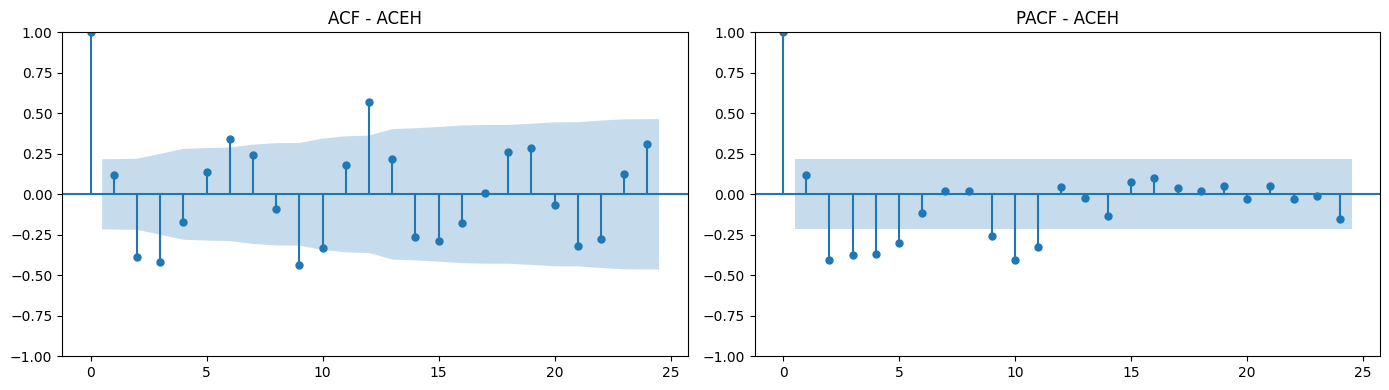

In [ ]:
# Plot ACF/PACF untuk satu provinsi. Gunakan seri yang telah ditransformasi
# sesuai hasil uji stasioneritas; contoh berikut memakai differencing pertama.
y_ident = panel[contoh_provinsi]['train']['Y'].diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_ident, lags=24, ax=axes[0])
plot_pacf(y_ident, lags=24, method='ywm', ax=axes[1])
axes[0].set_title(f'ACF - {contoh_provinsi}')
axes[1].set_title(f'PACF - {contoh_provinsi}')
plt.tight_layout()
plt.show()